# <center>VAI Academy</center>
# <center> Aquisição e Preparação de Dados - Parte 3</center>
___

# <center> Objetivos de aprendizado </center>
- Conhecer as etapas básicas de limpeza de dados: string parsin, conversão e combinação de dados, seleção de colunas e tratamento de dados ausentes
___

## Conteúdo
3. [Limpeza e preparação de dados](#datac) <br>
4. [Aprofunde-se](#digdeeper)

<a id="dsprecap"></a>
## Recapitulando: Data Science Pipeline (DSP)
1. Entendimento do Problema / Definição de Escopo
2. Definição de Objetivo e Configuração de Métricas
3. Determinação dos Dados Necessários
4. Aquisição de Dados
5. Limpeza de Dados & Manipulação
6. Análise Exploratória de Dados (E.D.A.)
7. Engenharia de Atributos
8. Construção e Avaliação do Modelo
9. Interpretação de Resultados & Relatório / Data Storytelling
10. Implantação
11. Monitoramento e Manutenção

**Esta aula contemplará os conceitos dos passos 4 e 5.**

<a id="datac"></a>
## 3. Limpeza e preparação de dados

Bem, nós temos nossos dados, mas é muito comum no mundo real que os dados não estejam limpos. Precisamos limpá-los, pois o princípio do Garbage-In-Garbage-Out acontecerá na modelagem. Melhores dados levam a melhores modelos. Mas antes de começarmos a entender os métodos, devemos nos perguntar: o que é um conjunto de dados limpo? <br>
Resumindo, a resposta não se trata de limpeza, mas sim de representatividade. Seus dados são uma amostra do mundo real, e devem ser o mais próximo possível da distribuição real. Na maioria das vezes, suas decisões de limpeza têm consequências tendenciosas, e você deve estar sempre atento a elas.

De fato, é comumente dito que os cientistas de dados gastam 80% de seu tempo limpando e manipulando dados, e apenas 20% de seu tempo realmente os analisando.

Agora vamos passar pelas formas mais comuns de manipulação de nossos dados.
- String parsing
- Conversão de dados
- Combinando dados
- Subconjunto de dados
- Tratamento de dados ausentes
- Tratamento de outliers

### 3.1. String parsing
String parsing consiste em analisar uma string para encontrar tokens, ou itens, e depois criar uma estrutura a partir do resultado. Isto é importante porque, em quase todos os datasets, as strings normalmente não aparecem como gostaríamos que aparecessem. Algumas vezes as strings seguem um formato muito simples, e algumas vezes são muito complicadas. Nesta seção, analisaremos algumas maneiras de converter strings em algo com que possamos raciocinar e trabalhar.

#### 3.1.1. Dividindo uma coluna com ```.str```.
A seguir, há um pequeno extrato de alguns dados que consistem em contagens de casos de tuberculose por país, sexo e faixa etária. Aqui, "*m5564*" significa um homem entre 55 e 64 anos de idade. Ou seja, as variáveis sexo e faixa etária estão concatenadas nesta sequência e gostaríamos de tê-las separadas em duas colunas diferentes.

| country |	group |	count|
|:-------:|:-----:|:-----|
|   VE    |	m5564 |	- |
|   BT    |	m3544 |	30.0 |
|   KE    |	f4554 |	831.0 |
|   MD    |	f2534 |	32.0 |
|   NZ    |	f3544 |	5.0 |
|   RW    |	f2534 |	473.0 |
|   MG    |	f2534 |	- |
|   MW    |	m2534 |	1476.0 |
|   PY    |	f1524 |	69.0 |
|   BZ    |	m3544 |	2.0 |

Como você pode separar os valores por posição, você pode aproveitar a string vetorizada do pandas utilizando o atributo ```str``` das colunas do tipo objeto.

#### Exemplo 3.1
Podemos usar o índice para extrair o gênero, já que ele aparece na primeira posição e tem um único caractere.

In [ ]:
# Instalando alguns pacotes necessários ao longo do notebook
# ATENÇÃO:  Após instalar as bibliotecas reinicie o ambiente de execução para garantir que está usando a versão correta
!pip install xlrd==2.0.1
!pip install pandas==2.1.1

In [ ]:
# importando bibliotecas
import os
import pandas as pd

#Mapeando todos os arquivos utilizados na aula - Veja Parte I
# pega atual diretório de trabalho, isto é a pasta em que está esse notebook, e armazena-o em wd
wd = os.getcwd()
print(wd)

# cria o caminho para a pasta dados
wd_data = wd + '/dados'
print(wd_data)

# lista os arquivos na pasta dados
if not os.path.exists(wd_data):
  os.makedirs(wd_data)
os.listdir(wd_data)

In [ ]:
d = {'country': ['VE','BT','KE','MD','NZ','RW' ,'MG','MW','PY','BZ'],
     'group':   ['m5564','m3544','f4554','f2534','f3544','f2534','f2534','m2534','f1524','m3544'],
     'count':   ['-','30.0','831.0','32.0','5.0','473.0','-','1476.0','69.0','2.0']}
df = pd.DataFrame(data=d)
df['gender'] = df.group.str[0]
df

#### 3.1.2. Dividindo uma coluna com ```.split()``` e ```.get()```
Outra forma comum de armazenar variáveis múltiplas em colunas é com um delimitador. Nesse caso, elas não precisam ter um número específico de caracteres para que possamos dividí-las, como no caso anterior. Agora podemos utilizar o método embutido chamado ```.split()```, que retornará uma lista dos tokens separados como strings.

Para esta subseção, estaremos utilizando um dataframe de 18 Jogadores da FIFA. Dê uma olhada nos valores da variável *qualidade*.

In [ ]:
# Carrega o dataset
players_DF = pd.read_csv('dados/class_2_fut_players.csv', sep=',')

# Mostra a tabela frequencia da variável qualidade
# NB: Na aula de Estatística, nós usamos o método de crosstab.
# Outra forma comum é mostrar essa informação com o método value_counts
players_DF.quality.value_counts()

#### Exemplo 3.2
Suponhamos que queremos duas colunas separadas para conhecer a qualidade e a raridade do jogador. Para isso, primeiro precisamos dividir a string pelo espaço em branco e depois utilizar o índice com o método ```.get()``` do atributo ```str``` na lista resultante para atribuí-las à sua respectiva variável.

In [ ]:
# Divide a variável de qualidade pelo delimitador padrão " " (espaço)
players_DF['quality_split'] = players_DF.quality.str.split()

# Pega o primeiro token, que representa a qualidade (bronze, prata ou ouro)
players_DF['quality_0'] = players_DF.quality_split.str.get(0)

# Mostra a frequência em cada qualidade
print(players_DF.quality_0.value_counts())

In [ ]:
players_DF.head(2)

### 3.2. Conversão de dados

Como vimos, os dados quase nunca vêm como gostaríamos que viessem. E, uma das razões é porque **os tipos de dados às vezes são bagunçados**. Nosso trabalho aqui é limpá-los e **tratá-los de acordo com o que representam**, não apenas como se fossem strings. Caso contrário, não seríamos capazes de obter o melhor desta informação nem de realizar operações matemáticas com eles. Onde não pudermos inferir o tipo a partir dos dados o Pandas irá atribuir o tipo padrão ```Object``` à variável.

#### 3.2.1. Tipo de dados numéricos
Às vezes, os números vêm como strings quando os carregamos. Este cenário em particular geralmente ocorre quando há valores ausentes e codificados como alguns caracteres, ou quando diferentes separadores decimais (vírgula ou ponto) são usados.

No Pandas, o tipo ```Object``` é o tipo padrão e é utilizado para codificar dados de strings.

Como sempre, é realmente importante ver como são nossos dados. Para isso, temos métodos como ```head()``` e ```info()```. Exiba esses métodos na célula a seguir.

In [ ]:
d = {'country': ['VE','BT','KE','MD','NZ','RW','MG','MW','PY','BZ'],
     'group':   ['m5564','m3544','f4554','f2534','f3544','f2534','f2534','m2534','f1524','m3544'],
     'count':   ['-','30.0','831.0','32.0','5.0','473.0','-','1476.0','69.0','2.0']}
df = pd.DataFrame(data=d)
df.info()
df.head()

Observe que  ```count``` deve ser um número e não um tipo de dado ```object```. Isto se deve à falta dos valores codificados como "-". Felizmente, o Pandas tem um método, ```to_numeric()```  para convertê-lo para um tipo numérico. Este método tem um argumento chamado ```errors```, no qual você pode especificar como você gostaria que o Pandas tratasse os erros:

* Se ```='raise'```, então o caractere inválido levantará uma exceção.
* Se ```='coerce'```, então o caractere inválido será definido como NaN
* Se ```='ignore'```, então o caractere inválido retornará a entrada

Há muitas opções para o que você deve fazer com os valores ausentes. Elas serão abordadas mais tarde nesta aula, não se preocupe. Observe o exemplo abaixo.

In [ ]:
df['count'] = pd.to_numeric(df['count'], errors='coerce')

print(df.head())
print()
print(df.info())

#### 3.2.2. Tipo de dados categóricos

Algumas variáveis podem ser categóricas e não numéricas. Neste caso, elas às vezes assumem uma faixa de **valores possíveis**. No Pandas, e geralmente em outras bibliotecas ou linguagens de programação, podemos **converter as strings que representam dados categóricos para um tipo de dados chamado ```category```**. A vantagem disso é que torna **mais fácil para os modelos realizarem operações** sobre eles. E também, **ocupam menos memória**!

No Pandas, para converter entre diferentes tipos de dados, existe um método chamado ```.astype()```, no qual você pode passar o tipo de dados como argumento.

In [ ]:
players_DF['quality_0'] = players_DF.quality_0.astype('object')
str_data = players_DF[['quality_0']] # Cria um dataframe com apenas a coluna quality_0

# Altere o tipo de dado para categoria
players_DF['quality_0'] = players_DF.quality_0.astype('category')
cat_data = players_DF[['quality_0']] # Cria um dataframe com apenas a coluna quality_0

print('Valores exclusivos de Qualidade: ', str_data.quality_0.unique(), '\n')
str_data.info()
print()
cat_data.info()

Vê quanta memória economizamos se usarmos o tipo de dados de categoria?

#### 3.2.3. Datas

Há muitas sintaxes diferentes para especificar valores de datas. Podemos até ter padrões diferentes nos mesmos dados. Confira as seguintes variáveis do conjunto de dados ```players_DF``` e seus tipos de dados (```dtype```).

In [ ]:
print(players_DF.added_date.head())
print(players_DF.date_of_birth.head())

No Pandas, há também uma função para converter valores para o tipo data/hora. Esta função é chamada de [```to_datetime()```](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) e tem uma série de **argumentos** diferentes nos quais é possível **especificar o formato da data de entrada**. Além disso, há um argumento ```infer_datetime_format``` que, se definido como True, irá **inferir o formato de seu input** sem ter que conhecê-la em primeira mão. Dê uma olhada nos exemplos abaixo.

In [ ]:
# Input: data como inteiro com unit = dias
# First day : 1970-01-01 00:00:00
print(pd.to_datetime(365*49, unit='D'))
print()

# Input: data  como inteiro com unit = seconds
print(pd.to_datetime(1490195805, unit='s'))
print()

# Input: yyyy-mm-dd com infer_datetime_format=True
print(pd.to_datetime(players_DF.added_date, infer_datetime_format=True).head())
print()

# Input: dd/mm/yyyy com infer_datetime_format=True
print(pd.to_datetime(players_DF.date_of_birth, infer_datetime_format=True).head())
print()

# Input: dd/mm/yyyy
# Output: Em UTC DatetimeIndex
print(pd.to_datetime(players_DF.date_of_birth, infer_datetime_format=True, utc=True).head())
print()

### 3.3. Combinação de dados

#### 3.3.1. Função Concat
Às vezes nosso dataset será dividido em diferentes partes e precisamos combiná-las. Pandas [```pd.concat()```](https://pandas.pydata.org/docs/reference/api/pandas.concat.html) pode unir dados em linhas ou em colunas especificando o parâmetro ```eixo```.

* Combinando linhas de dados (padrão ```eixo=0```)
* Combinando colunas de dados (```eixo=1```)

Na célula abaixo, temos mais extratos do conjunto de dados de tuberculose que usamos na seção anterior.

In [ ]:
df1 = pd.DataFrame(data={
    'country': ['VE','BT','KE','MD','NZ','RW','MG','MW','PY','BZ'],
    'group':   ['m5564','m3544','f4554','f2534','f3544','f2534','f2534','m2534','f1524','m3544'],
    'count':   ['-','30.0','831.0','32.0','5.0','473.0','-','1476.0','69.0','2.0']
})

df2 = pd.DataFrame(data={
    'country': ['MP','CK','MY','SZ','LT','MX','TN','NU'],
    'group':   ['m4554','f3544','f3544','m4554','f4554','f4554','f4554','f1524'],
    'count':   ['9.0','0.0','424.0','138.0','32.0','832.0','21.0','NaN']
})

df3 = pd.DataFrame(data={
    'country': ['BB','EC','AR','CI','TM','PY','TC'],
    'group':   ['f5564','m0014','f5564','f3544','f1524','f4554','m5564'],
    'count':   ['0.0','NaN','179.0','NaN','73.0','41.0','NaN']
})

# Exiba cada shape do dataframe
print('df1 shape:', df1.shape)
print('df2 shape:', df2.shape)
print('df3 shape:', df3.shape)

Suponha que queremos unir as linhas dos três dataframes ```df1```, ```df2``` e ```df3``` em um único, para isso vamos utilizar a função ```pd.concat()```.

In [ ]:
# cria a lista do dataframe
df_list = [df1, df2, df3]

# concatena a lista
# note que os índices estarão duplicados. Utilizamos ignore_index=True para que isso não ocorra
df = pd.concat(df_list, ignore_index=True)

# Exiba o shape do dataframe resultante
df.shape

#### 3.3.2. Fusão de dados (merge)
Outra forma comum de combinar os dados é através da função "merge", que realiza joins como os da linguagem SQL. Vamos apresentar os tipos de fusões que podem ser realizados.

* **1-to-1 data merge**: aqui temos uma correspondência de um para um nos dataframes. Portanto, não será replicado nenhum dado.

In [ ]:
A = pd.DataFrame(data={
    'c1': ['a', 'b'],
    'c2': [1, 2]
})
B = pd.DataFrame(data={
    'c1': ['b', 'a'],
    'c2': [10, 20]
})

C = pd.merge(left=A, right=B, on='c1')

# Printa o dataframes
print(A,'\n') # \n é um caractere especial para uma nova linha
print(B,'\n')
print(C,'\n')

* **Many-to-1 data merge**: como temos chaves duplicadas no df ```A```, os valores de ```B``` serão replicados.

In [ ]:
import numpy as np

A = pd.DataFrame(data={
    'c1': 2*['a'] + 2*['b'],
    'c2': np.arange(4)
})
B = pd.DataFrame(data={
    'c1': ['a', 'b'],
    'c2': [10, 20]
})

C = pd.merge(left=A, right=B, on='c1')

# Printa os dataframes
print(A,'\n') # \n é um caractere especial para uma nova linha
print(B,'\n')
print(C,'\n')

* **Many-to-Many data merge**: aqui temos chaves duplicadas em ambos os dataframes. Assim, o resultado terá todas as combinações possíveis de valores.

In [ ]:
A = pd.DataFrame(data={
    'c1': 2*['a'] + 2*['b'],
    'c2': np.arange(4)
})
B = pd.DataFrame(data={
    'c1': 2*['a'] + 2*['b'],
    'c2': 10*np.arange(4)
})

C = pd.merge(left=A, right=B, on='c1')

# Printa o dataframe
print(A,'\n') # \n é um caractere especial para uma nova linha
print(B,'\n')
print(C,'\n')

Entender como nossos dados são estruturados em diferentes datasets é importante quando estamos dando merge. Temos que dar uma atenção especial ao aspecto de nossa chave.

A melhor prática é aproveitar as funções comuns do pandas (tais como  ```head()```, ```info()```, ```describe()```, ```value_counts()```) para conhecer seu dataset.

### 3.4. Removendo colunas desnecessárias

Há várias maneiras de lidar com colunas e limpeza de dados.<br>
Depois de carregar um dataset, poderíamos utilizar o método ```.drop``` para remover algumas colunas desnecessárias de nosso dataframe.

In [ ]:
exclude_columns = ['pass_crossing','phys_stamina',
                   'gk_reflexes','phys_strength']

players_drop_DF = players_DF.drop(exclude_columns, axis=1)
print(players_drop_DF.shape, players_DF.shape)

Quando ```axis=1``` é especificado que a busca de exclusão será em colunas. Se você utilizar 0, serão excluídos os índices com esses valores. <br>
Para apagar a coluna sem precisar reatribuir a outro Dataframe, você pode utilizar ```inplace=True``` para fazer esta mudança dentro do Dataframe.

Da última vez na aula de Pandas, vimos algumas maneiras de selecionar colunas de um Dataframe.<br>
Agora, vamos utilizar a opção ```usecols``` do método ```.read_csv``` para carregar apenas algumas colunas, e não todo o dataset.

In [ ]:
datset_columns = ('player_id','player_name','player_extended_name',
                  'origin','date_of_birth','club','league','position',
                  'height','weight')


players_reduced_DF = pd.read_csv('dados/class_2_fut_players.csv',sep=',',
                        usecols=datset_columns)

In [ ]:
#Utilização de memória convertido de bytes para megabytes
print(round(players_DF.memory_usage(deep=True).sum()/1024 ** 2))
print(round(players_reduced_DF.memory_usage(deep=True).sum()/1024 ** 2))

Ótimo! Carregamos apenas aquelas colunas sem consumir tanta memória<br>
Carregar apenas as colunas desejadas pode consumir menos memória quando se trabalha com grandes datasets. Além disso, evita algumas operações desnecessárias quando já sabemos quais colunas devem ser utilizadas.

### 3.5. Removendo Dados Duplicados

Remover valores duplicados em seus dados é uma etapa comum da limpeza de dados.<br>
Uma função do Pandas muito útil nos ajudará a lidar com isso, chamada ```drop_duplicates```.
<br>

Essa função retorna um Dataframe sem linhas duplicadas.<br>
Podemos utilizar o parâmetro ```keep``` para manter um registro de valores duplicados <br>
'first' - mantém a primeira ocorrência <br>
'last'- mantém a última ocorrência <br>
False - remove todas as linhas duplicadas <br>

Imagine que você quer obter apenas o último registro para cada jogador.<br>
Passando a coluna para verificar valores duplicados para ```.drop_duplicates```

*Observação*: Note que existem vários jogadores com o mesmo apelido('player_name') e até jogadores com mesmo nome('player_extended_name') e datas de nascimento('date_of_birth') diferentes.

In [ ]:
players_reduced_DF.drop_duplicates(['player_extended_name', 'date_of_birth'], keep='last').shape

Mas, se você quiser verificar quais valores foram duplicados, a função ```.duplicated``` retornará todas as linhas duplicadas.<br>
```keep=False``` devolverá todas as instâncias duplicadas

In [ ]:
players_reduced_DF[players_reduced_DF.duplicated('player_extended_name',
                                                 keep=False)]\
.sort_values('player_extended_name')\
.head(5)

Outra maneira de obter valores únicos de uma coluna ou série - <i> lembre-se, uma coluna de dataframe pode ser tratada como um objeto da série Pandas </i>- utilizando o método ```.unique``` da biblioteca NumPy, ou objeto do Python ```set()```.

In [ ]:
players_reduced_DF['player_extended_name'].unique()

In [ ]:
set(players_reduced_DF['player_extended_name'])

### 3.6. Filtrando apenas Informações Necessárias

#### 3.6.1. Loc e iloc

Ambos os métodos são úteis para filtrar um dataset usando alguns critérios.<br>
```.loc``` utiliza o valor do índex.<br>
```.iloc``` utiliza a posição do índex.<br>


In [ ]:
players_DF.loc[players_DF.nationality == 'Brazil'].head()

In [ ]:
players_DF.loc[5]

**Dica**<br>
O método Loc é muito útil para preencher ou substituir valores baseados em uma condição, pois o método retorna todo o dataset sem alterar os valores e a posição do índice.<br>
Por exemplo, poderíamos mudar a coluna **player_id** para o valor 99999 para jogadores brasileiros.<br> **Mas preste atenção, esta ação substituirá diretamente no dataframe**.

In [ ]:
players_DF.loc[players_DF.nationality == 'Brazil', ['player_id']] = 99999
players_DF.head()

#### 3.6.2. isin

Às vezes, é útil construir uma lista com valores que queremos filtrar em um dataset

In [ ]:
filter_values = ['Brazil','Argentina', 'Italy', 'France']
players_DF[players_DF['nationality'].isin(filter_values)].head()

Talvez... valores **not in** uma lista.<br>
Usando o caractere **~** antes do filtro

In [ ]:
players_DF[~players_DF['nationality'].isin(filter_values)].head()

#### 3.6.3. Filter

Imagine que você quer filtrar apenas as colunas para os atributos do goleiro. O método ```.filter``` com parâmetro ```regex``` pode selecionar somente as colunas começando com **gk_**

In [ ]:
gk_attributes_DF = players_DF.filter(regex=("gk_*"))
gk_attributes_DF.head(1)

In [ ]:
gk_cols = players_DF.columns[players_DF.columns.str.startswith("gk_")]
gk_cols

In [ ]:
gk_cols = players_DF.columns[players_DF.columns.str.startswith("gk_")]

gk_attributes_DF_ = players_DF.filter(items=gk_cols)
gk_attributes_DF_.head(1)

Podemos combinar os métodos ```.sort_values``` e  ```.iloc``` para mostrar o nome (**player_name**), por exemplo, do 3° melhor jogador no atributo **pace_sprint_speed**.<br>

In [ ]:
#Devemos utilizar o index 2 para retornar a terceira posição.
print(players_DF.sort_values('pace_sprint_speed', ascending=False).iloc[2]['player_name'])

### 3.7. Dados ausentes

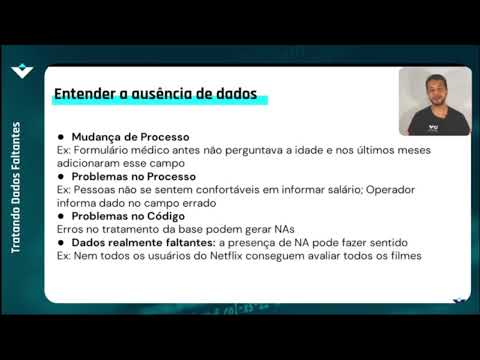

In [1]:
from IPython.display import YouTubeVideo
YouTubeVideo('Me5NrJlBeic', width = 640, height = 360)

Como vimos no vídeo, há algumas maneiras para lidar com dados ausentes (missing data):
1. Remover a linha que contenha dados ausentes
2. Criar uma categoria para dados ausentes
3. Substituir NAs por outros valores, tais como média, mediana ou moda

Agora vamos colocar em prática. Primeiro, vamos olhar para o conjunto de dados.

In [ ]:
# total de NA para cada coluna
# isnull() detecta valores ausentes (retorna um dataframe booleano com a mesma forma do input)
# sum() somará os valores ao longo da linha do dataframe. Note que True é representado como 1
# e Falso como 0
print(players_DF.isnull().sum())

Podemos notar que a coluna ```pace``` tem alguns valores ausentes. Vamos agora aprender como aplicar os métodos listados acima.

Primeiro, vamos entender o método para retirar NA. Para isso, existe um método chamado ```dropna()``` da biblioteca pandas, que faz exatamente isso. Alguns argumentos importantes desta função são:
- ```subset```: define em quais colunas procurar os valores ausentes.
- ```axis```: determina se as linhas ou colunas que contêm valores ausentes são removidas.

Agora é o momento de testar esta função:

In [ ]:
# Drop NA
players_DF_drop_na_pace = players_DF.dropna(axis=0, subset=['pace'])

# Retorna somente linhas com valores de NA
# any() toma como entrada uma lista booleana e retorna
#     Verdadeiro, se algum dos elementos for Verdadeiro
#     e Falso, caso contrário
# Como temos dados bidimensionais, temos de especificar o eixo em que
# vamos desempenhar esta função. eixo=1 retornará Verdadeiro se qualquer
# elemento na linha for Verdadeiro

players_DF_drop_na_pace[players_DF_drop_na_pace.isnull().any(axis=1)].head(3)

In [ ]:
# conta as linhas  e colunas do raw dataset
print(players_DF.shape)

# conta as linhas e colunas depois de dropar NA
print(players_DF_drop_na_pace.shape)

Outra maneira possível de tratar os valores NA é substituí-los por outros valores, por exemplo: média, mediana ou moda. Vamos agora utilizar o método ```fillna```, como a seguir.

In [ ]:
# Preenche os NAs para a coluna "pace"
players_DF_fill_na_pace = players_DF.copy()

# Substitui NA pela média
players_DF_fill_na_pace['pace'] = players_DF_fill_na_pace['pace'].fillna(players_DF_fill_na_pace['pace'].mean())

# conta as linhas e colunas
print(players_DF_fill_na_pace['pace'].shape)

# verifica se há NAs
print(players_DF_fill_na_pace['pace'].isnull().sum())

O último método dessa aula para tratar dados ausentes é criar uma nova categoria para esses valores. Note que este método é apropriado para valores categóricos.

In [ ]:
# Fill NA para a coluna "origin"
players_DF_fill_na_origin = players_DF.copy()
new_category = 'Missing'

# Substitui NA pela média
players_DF_fill_na_origin['origin'] = players_DF_fill_na_origin['origin'].fillna(new_category)

# conta linhas e colunas
print(players_DF_fill_na_origin['origin'].shape)

# verifica se há NA no raw dataset
print(players_DF['origin'].isnull().sum())

# conta linhas que foram substituidas
print((players_DF_fill_na_origin['origin'] == "Missing").sum())

### 3.8. Outliers

In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo('r8lZGGA347k', width = 640, height = 360)

A fim de tratar os outliers que acreditamos que devem ser removidos da base, podemos usar o conceito de [distância interquartil](https://pt.wikipedia.org/wiki/Amplitude_interquartil). Para isso, vamos criar uma função chamada ```drop_outliers``` que fará esse processo. Note que antes de remover qualquer outlier é necessário ter tratado os valores ausentes

In [ ]:
# Copia o dataset com a coluna tratada
players_DF_outliers_pace = players_DF_fill_na_pace.copy()

def drop_outliers(df, feature):
    outliers = []
    # Calcula o Q1 (25° percentil) da feature
    Q1 = np.percentile(df[feature], 25)

    # Calcula Q3 (75° percentil) da feature
    Q3 = np.percentile(df[feature], 75)

    # Utiliza a distância interquartil para calcular o passo do outlier
    step = 1.5 * (Q3 - Q1)

    feature_outliers = df[~((df[feature] >= Q1 - step) & (df[feature] <= Q3 + step))]
    outliers.extend(list(feature_outliers.index.values))

    return outliers


outliers = drop_outliers(players_DF_outliers_pace, 'pace').copy()
players_DF_outliers_pace = players_DF_outliers_pace.drop(players_DF_outliers_pace.index[outliers]).reset_index(drop = True)

# Verifica o número de colunas no dataset antes de remover os outliers
print(players_DF_fill_na_pace.shape[0])

# Verifica o número de colunas no dataset após a remoção de outliers
print(players_DF_outliers_pace.shape[0])

### 3.9. Reformatando o dataframe

Os dados vêm em uma variedade de formas e formatos. Às vezes são apresentados de um modo mais intuitivo, mas não estão adequados para análise e vice-versa. Dê uma olhada no exemplo abaixo.

#### Exemplo 3.4

* Formato 1:

| **Nome** | **Tratamento A** | **Tratamento B** |
|------|-------------|-------------|
|Daniel|  - | 42 |
| John | 12 | 31 |
| Jane | 24 | 27 |

* Formato 2:

| **Nome** | Daniel | John | Jane |
|----------|--------|------|------|
| **Tratamento A** |  - | 12 | 24 |
| **Tratamento B** | 42 | 31 | 27 |

Observe que os mesmos dados são exibidos por duas maneiras diferentes. A fim de **padronizar** a forma como representamos os dados **para análise**, geralmente tendemos a seguir algumas regras simples:
1. **Colunas representam variáveis separadas**.
2. **Linhas representam observações individuais**.

#### 3.9.1. Derretimento (melting) de seus dados
Observe que nenhuma das representações acima segue estas duas regras. O primeiro formato (discutivelmente) viola a primeira regra, pois ***Tratamento A* e *Tratamento B* representam a mesma variável**, eles apenas diferem no processo de obtenção (que pode ser considerada como a variável *Tratamento*). O segundo formato viola a segunda regra, pois as linhas não representam **diferentes observações** (as colunas sim). Portanto, um bom formato para análise de dados poderia ser:

| **Nome** | **Tratamento** | **Valor** |
|------|-------------|-------------|
|Daniel| A | - |
| John | A | 12 |
| Jane | A | 24 |
|Daniel| B | 42 |
| John | B | 31 |
| Jane | B | 27 |

Note que esta não é a melhor maneira de reportar os dados. Mas, como explicado, há sempre um **trade-off entre sua exibição e sua análise**.

No mundo real, comumente encontramos situações em que os valores são representados em diferentes colunas. Para corrigir isso, podemos utilizar uma função Pandas chamada ```.melt()```. Há dois parâmetros que você deve estar ciente: ```id_vars``` e ```value_vars```. Os ```id_vars``` representam as colunas dos dados que você **não quer fazer um melt** (ou seja, mantê-los em sua forma atual), enquanto os ```value_vars``` representam as colunas que você **quer dar melt para linhas**. Por padrão, se não forem fornecidas as ```value_vars```, todas as colunas não definidas no ```id_vars``` serão derretidas. Isto poderia economizar um pouco de digitação, dependendo do número de colunas que precisam ser despivoteadas.

#### Exemplo 3.5
Utilizando a função ```pd.melt()``` podemos derreter as colunas ```Tratamento``` e ```Valor``` em linhas.

In [ ]:
df = pd.DataFrame(data={
    'Nome': ['Daniel', 'John', 'Jane'],
    'Tratamento A': [np.nan, 12, 24],
    'Tratamento B': [42, 31, 27]
})
df

In [ ]:
df_melt = pd.melt(df, id_vars=['Nome'])
df_melt

In [ ]:
# Podemos especificar os nomes das colunas, nomes de variáveis e valores
# ao invés dos nomes padrões através dos argumentos var_name e value_name
df_melt = pd.melt(df, id_vars='Nome', var_name='Tratamento', value_name='Score')
df_melt

#### 3.9.2. Pivoteando seu dado

Pivotear os dados é o oposto de derretê-los (melt também é conhecido como unpivot). Isto é, enquanto melt pega um conjunto de colunas e as transformam em uma única coluna, o pivot criará uma nova coluna para cada valor único em uma coluna especificada. No Pandas, isto pode ser feito com o método ```.pivot_table()``` de um dataframe. Ele tem o parâmetro ```index``` que você pode utilizar para especificar as colunas que você **não quer que sejam pivotadas**: É semelhante ao parâmetro ```id_vars``` de ```pd.melt()```. Dois outros parâmetros que você tem que especificar são ```columns``` (o nome da coluna que você deseja pivotear), e ```values``` (os valores a serem utilizados quando a coluna for pivoteada).

#### Exemplo 3.6

In [ ]:
df_pivot = df_melt.pivot_table(index='Nome', columns='Tratamento', values='Score')
df_pivot

<a id="digdeeper"></a>
## 4. Aprofunde-se

* Data Cleaning
 - [The cleaning mindset tutorial](https://towardsdatascience.com/the-ultimate-guide-to-data-cleaning-3969843991d4)
 - [Best practices](https://towardsdatascience.com/data-cleaning-101-948d22a92e4)
 - [The importante of cleaning the right way](https://medium.com/@ODSC/the-importance-of-processing-data-the-right-way-3a93775a55e2)
 - [Make your cleaning tools](https://towardsdatascience.com/the-simple-yet-practical-data-cleaning-codes-ad27c4ce0a38)

<a id="pan"></a>
## Fim da Aula!
Após essa aula, esperamos que você tenha entendido a importância de tratar previamente as bases de dados antes de trabalhar sobre elas, garantindo assim a fidelidade dos resultados das suas análises.
Certifique-se de tirar todas suas dúvidas conosco!

Até a próxima aula!!